# Red neuronal recurrente para valorar la call asiática

La red lee la trayectoria de **WMT**, **MRK** y **NVDA** trimestre a trimestre y predice el **payoff** de la opción. Aprende de las **100.000 simulaciones** de **montecarlo.ipynb**. La comparación de su prima con la del Montecarlo y la fórmula cerrada está en **resultados.ipynb**.

**Estructura del notebook**
- **Preparación y herramientas**: carga de las simulaciones, reparto en train (80 %), validación (10 %) y test (10 %), la red y el entrenamiento.
- **Bloque 1, red base**: **RNN**, **LSTM** y **GRU** con la configuración más simple, para decidir cuáles pasan al bloque 2.
- **Bloque 2, red profunda**: búsqueda de hiperparámetros en dos rondas (learning rate, scheduler, capas, dropout y neuronas) con 20.000 simulaciones. El modelo final de la **LSTM** y de la **GRU** se entrena con las 100.000 y con 3 semillas.
- **Bloque 3, trayectorias cortadas**: la red, sin reentrenar, con la trayectoria cortada por el final (de T19 a T16) y la prima que da con 1 a 20 trimestres vistos.
- **Conclusiones**.

Al ejecutarlo se entrenan todas las redes desde cero y se guardan en la carpeta **modelos/**, sustituyendo a las anteriores. Con las 100.000 simulaciones tarda unas tres horas y media (la última ejecución completa fueron 214 minutos).

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # PyTorch y matplotlib traen cada uno su OpenMP en Windows

import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

AZUL, ROJO, GRIS = "#001391", "#FF4B4B", "#8A8D91"   # paleta del proyecto

---
# Preparación de los datos


**montecarlo.ipynb** guarda en **Datos/resultados_montecarlo.npz** las trayectorias simuladas (**x**) y el payoff de cada simulación.

In [2]:
datos = np.load("Datos/resultados_montecarlo.npz")
X, payoff = datos["x"], datos["payoff"]
print("X:", X.shape, "-> (simulaciones, trimestres, acciones)")
print("payoff:", payoff.shape, "-> uno por simulación")

X: (100000, 20, 3) -> (simulaciones, trimestres, acciones)
payoff: (100000,) -> uno por simulación


#### Reparto en train, validación y test

La entrada es **log(X)**: los precios van de 0,01 a 50 y en logaritmo quedan cerca de 0. La salida es el **payoff**.

Las simulaciones se reparten **al azar**: 80 % para entrenar, 10 % para validación y 10 % para test.

- Para **comparar configuraciones** (bloques 1 y 2) usamos **20.000 simulaciones**. Así cada entrenamiento tarda minutos y no horas, y 20.000 trayectorias bastan para ver qué configuración aprende mejor.
- Las configuraciones se eligen con el error en **validación**. El **test** se reserva para el modelo final, que se entrena con las **100.000**.

In [3]:
X_t = torch.tensor(np.log(X), dtype=torch.float32)               # (100000, 20, 3)
Y_t = torch.tensor(payoff, dtype=torch.float32).unsqueeze(-1)    # (100000, 1)


def repartir(n):
    """Reparte al azar las n primeras simulaciones en train (80 %), validación (10 %) y test (10 %)."""
    idx = torch.randperm(n, generator=torch.Generator().manual_seed(0))
    n_train, n_val = int(0.8 * n), int(0.1 * n)
    train, val, test = idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]
    return (DataLoader(TensorDataset(X_t[train], Y_t[train]), batch_size=256, shuffle=True),
            DataLoader(TensorDataset(X_t[val], Y_t[val]), batch_size=1024),
            DataLoader(TensorDataset(X_t[test], Y_t[test]), batch_size=1024))


N_BUSQUEDA = 20_000
dl_train, dl_val, dl_test = repartir(N_BUSQUEDA)
print("train:", len(dl_train.dataset), "| val:", len(dl_val.dataset), "| test:", len(dl_test.dataset))

train: 16000 | val: 2000 | test: 2000


---
# Herramientas

Funciones que usan todas las pruebas, para que se hagan **igual** y se puedan comparar.

#### La red recurrente

Un único molde para los tres tipos. La red lee los 20 trimestres, guarda un resumen en su memoria (el **estado oculto**, de 32 números) y con el del último trimestre una capa lineal da el payoff. Es una regresión: la salida no lleva activación y la pérdida es la **MSE**.

| Red | Memoria |
|---|---|
| **RNN** | Simple: en cada trimestre mezcla lo nuevo con lo que recordaba. Tiende a olvidar los primeros trimestres |
| **LSTM** | Tres puertas que deciden qué olvidar, qué guardar y qué usar |
| **GRU** | Una LSTM simplificada, con dos puertas |

El **dropout** de PyTorch solo actúa **entre capas recurrentes**, así que solo tiene efecto con 2 capas o más.

In [4]:
TIPOS = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}


class RedRecurrente(nn.Module):
    def __init__(self, tipo, capas=1, dropout=0.0, neuronas=32):
        super().__init__()
        self.rnn = TIPOS[tipo](input_size=3, hidden_size=neuronas, num_layers=capas, dropout=dropout, batch_first=True)
        self.salida = nn.Linear(neuronas, 1)

    def forward(self, x):
        h, _ = self.rnn(x)                  # (batch, 20 trimestres, neuronas)
        return self.salida(h[:, -1, :])     # estado del último trimestre

#### Entrenamiento y evaluación

**entrenar** repasa train época a época, mide el error en validación sin aprender de ella y guarda los pesos de la **mejor época**. Sin **paciencia** entrena todas las épocas; con paciencia para cuando lleva ese número de épocas sin mejorar. También mide el **tiempo**.

**experimento** entrena una red y la guarda en **modelos/**, y devuelve su fila para la tabla: parámetros, épocas, mejor época, minutos, **MSE**, **MAE** y **R²** en validación. Así, al volver a ejecutar el notebook, solo se entrena lo nuevo.

Con **decaimiento** (por ejemplo 0,95) el learning rate se multiplica por ese número al acabar cada época: empieza con pasos grandes y los va encogiendo para afinar.


In [5]:
perdida = nn.MSELoss()


def evaluar(modelo, dl):
    modelo.eval()
    with torch.no_grad():
        pred = torch.cat([modelo(xb) for xb, _ in dl])
        real = torch.cat([yb for _, yb in dl])
    return perdida(pred, real).item(), pred.squeeze(-1).numpy(), real.squeeze(-1).numpy()


def entrenar(modelo, ruta, dl_train, dl_val, epocas=40, lr=1e-3, paciencia=None, decaimiento=None):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=decaimiento) if decaimiento else None
    hist = {"train": [], "val": []}
    mejor, sin_mejora = float("inf"), 0
    inicio = time.time()
    for epoca in range(1, epocas + 1):
        modelo.train()
        total = 0.0
        for xb, yb in dl_train:
            opt.zero_grad()
            loss = perdida(modelo(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        if sched:
            sched.step()   # el learning rate se multiplica por el decaimiento al acabar la época
        hist["train"].append(total / len(dl_train.dataset))
        hist["val"].append(evaluar(modelo, dl_val)[0])
        print(f"época {epoca:3d} | train {hist['train'][-1]:.5f} | val {hist['val'][-1]:.5f}")
        if hist["val"][-1] < mejor or not os.path.exists(ruta):
            mejor, sin_mejora = hist["val"][-1], 0
            torch.save(modelo.state_dict(), ruta)
        else:
            sin_mejora += 1
        if paciencia and sin_mejora >= paciencia:
            break
    hist["segundos"] = time.time() - inicio
    modelo.load_state_dict(torch.load(ruta))   # pesos de la mejor época
    return hist


RUTA_HIST = "modelos/historial.json"
os.makedirs("modelos", exist_ok=True)
historial = {}                       # se entrena todo desde cero, y el historial se guarda tras cada red
redes = {}


def experimento(nombre, red, datos=None, **kw):
    """Entrena la red y devuelve su fila de resultados en validación."""
    dl_tr, dl_va = datos or (dl_train, dl_val)
    ruta = f"modelos/{nombre}.pt"
    print(f"\n{nombre}")
    historial[nombre] = entrenar(red, ruta, dl_tr, dl_va, **kw)
    with open(RUTA_HIST, "w") as f:
        json.dump(historial, f)
    redes[nombre] = red
    h = historial[nombre]
    mse, pred, real = evaluar(red, dl_va)
    return {"modelo": nombre, "parámetros": sum(p.numel() for p in red.parameters()),
            "épocas": len(h["val"]), "mejor época": h["val"].index(min(h["val"])) + 1,
            "minutos": h["segundos"] / 60, "MSE": mse, "MAE": abs(pred - real).mean(), "R²": 1 - mse / real.var()}


def curvas(nombres, titulo):
    """Error de train y de validación por época; la línea discontinua marca la mejor época."""
    fig, ejes = plt.subplots(1, len(nombres), figsize=(5 * len(nombres), 4), sharey=True, squeeze=False)
    for eje, nombre in zip(ejes[0], nombres):
        h = historial[nombre]
        epocas = range(1, len(h["val"]) + 1)
        mejor = h["val"].index(min(h["val"])) + 1
        eje.plot(epocas, h["train"], color=AZUL, label="train")
        eje.plot(epocas, h["val"], color=ROJO, label="validación")
        eje.axvline(mejor, color=GRIS, ls="--", lw=1, label=f"mejor época ({mejor})")
        eje.set(title=nombre, xlabel="Época", yscale="log")
        eje.legend()
    ejes[0][0].set_ylabel("MSE")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

---
# **BLOQUE 1**: Red base

**RNN**, **LSTM** y **GRU** con la configuración más simple y la misma para las tres. No buscamos la mejor red, sino ver cuál capta mejor la relación entre trayectoria y payoff y decidir cuáles pasan a la red profunda.

| Hiperparámetro | Valor |
|---|---|
| **Capas** | 1, de 32 neuronas |
| **Dropout** | 0 |
| **Learning rate** | 0,001 (Adam) |
| **Batch** | 256 |
| **Épocas** | 40 fijas, sin early stopping |

Con **40 épocas fijas** las tres redes entrenan lo mismo, así que si una gana no es por haber entrenado más. Además se ve si la curva **seguía bajando** al final, es decir, si le faltaba entrenamiento.

La primera fila de la tabla es la referencia: predecir siempre el **payoff medio de train**.

#### 1.1 Entrenamiento de RNN, LSTM y GRU

In [6]:
media = dl_train.dataset.tensors[1].mean().item()
real_val = dl_val.dataset.tensors[1].squeeze(-1).numpy()
filas = [{"modelo": "media de train (referencia)", "MSE": ((real_val - media) ** 2).mean(),
          "MAE": abs(real_val - media).mean(), "R²": 0.0}]

for tipo in ["RNN", "LSTM", "GRU"]:
    torch.manual_seed(0)
    filas.append(experimento(f"base_{tipo.lower()}", RedRecurrente(tipo), epocas=40, lr=1e-3))

tabla_base = pd.DataFrame(filas).set_index("modelo")
tabla_base.round(5)


base_rnn
época   1 | train 0.14489 | val 0.07246
época   2 | train 0.03196 | val 0.01269
época   3 | train 0.01397 | val 0.01041
época   4 | train 0.01114 | val 0.00844
época   5 | train 0.00928 | val 0.00646
época   6 | train 0.00840 | val 0.00500
época   7 | train 0.00583 | val 0.00330
época   8 | train 0.00452 | val 0.00239
época   9 | train 0.00410 | val 0.00284
época  10 | train 0.00345 | val 0.00174
época  11 | train 0.00295 | val 0.00185
época  12 | train 0.00282 | val 0.00281
época  13 | train 0.00274 | val 0.00166
época  14 | train 0.00254 | val 0.00180
época  15 | train 0.00256 | val 0.00143
época  16 | train 0.00220 | val 0.00194
época  17 | train 0.00214 | val 0.00125
época  18 | train 0.00224 | val 0.00143
época  19 | train 0.00213 | val 0.00158
época  20 | train 0.00186 | val 0.00105
época  21 | train 0.00178 | val 0.00291
época  22 | train 0.00219 | val 0.00139
época  23 | train 0.00187 | val 0.00113
época  24 | train 0.00191 | val 0.00099
época  25 | train 0.00165 | va

,MSE,MAE,R²,parámetros,épocas,mejor época,minutos
modelo,,,,,,,
media de train (referencia),0.22554,0.36037,0.00000,NaN,NaN,NaN,NaN
base_rnn,0.00068,0.01796,0.99697,1217.0,40.0,37.0,0.56626
base_lstm,0.00020,0.01001,0.99912,4769.0,40.0,40.0,0.67180
base_gru,0.00026,0.01185,0.99883,3585.0,40.0,35.0,1.10987


#### 1.2 Curvas de aprendizaje

Cada panel es una red. La línea azul es el error en train, la roja el error en validación y la línea discontinua marca la mejor época. El eje vertical está en escala logarítmica: bajar una división es tener diez veces menos error.

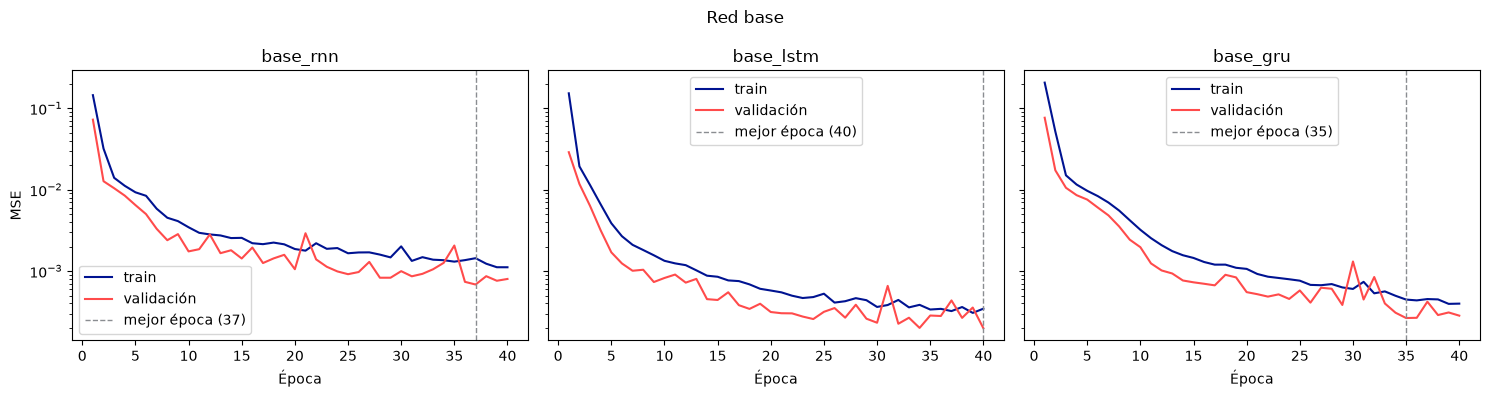

In [7]:
curvas(["base_rnn", "base_lstm", "base_gru"], "Red base")

#### 1.3 Conclusiones de la red base

La **LSTM** es la mejor de las tres: en validación se equivoca de media **0,010** en el payoff (R² de 0,9991), frente a **0,012** de la **GRU** y **0,018** de la **RNN**. La referencia, predecir siempre la media de train, se equivoca **0,360**.

- **LSTM:** su mejor época es la **40**, la última, así que **seguía mejorando** y le faltó entrenamiento.
- **GRU:** casi igual que la LSTM, con su mejor época en la **35** y las últimas casi planas.
- **RNN:** desde la época **20** su error se queda en torno a 0,001 y solo oscila. Su memoria simple **olvida los primeros trimestres**, y el payoff de la asiática depende de los 20.

En ninguna de las tres la validación se separa de train, así que **no hay sobreajuste**.

**La LSTM y la GRU pasan a la red profunda; la RNN no.** Como la LSTM seguía bajando en la época 40, en el bloque 2 entrenamos hasta 60 épocas con early stopping.

---
# **BLOQUE 2**: Red profunda

Buscamos la **mejor LSTM** y la **mejor GRU** con **2 capas recurrentes**, cambiando una cosa cada vez y eligiendo siempre con el error en **validación**.

| Paso | Qué cambia | Valores |
|---|---|---|
| **2.1** | Learning rate, sin dropout | 0,01 · 0,001 · 0,0001 |
| **2.2** | Dropout entre las dos capas, con el mejor learning rate | 0 · 0,2 |
| **2.3** | Neuronas por capa, con el mejor learning rate y dropout | 32 · 64 |
| **2.4** | Modelo final con las **100.000** simulaciones y evaluación en **test** | |

Como no sabemos cuántas épocas necesita cada configuración, entrenamos hasta **60** con early stopping de **paciencia 10**.

Esto es la **ronda 1**. Más abajo, la **ronda 2** amplía las rejillas con lo aprendido aquí.

#### 2.1 Learning rate


In [8]:
LRS = [1e-2, 1e-3, 1e-4]

filas = []
for tipo in ["LSTM", "GRU"]:
    for lr in LRS:
        torch.manual_seed(0)
        filas.append(experimento(f"prof_{tipo.lower()}_lr{lr:g}", RedRecurrente(tipo, capas=2),
                                 epocas=60, lr=lr, paciencia=10))

tabla_lr = pd.DataFrame(filas).set_index("modelo")
mejor_lr = {tipo: min(LRS, key=lambda lr: tabla_lr.loc[f"prof_{tipo.lower()}_lr{lr:g}", "MSE"]) for tipo in ["LSTM", "GRU"]}
print("Mejor learning rate:", mejor_lr)
tabla_lr.round(5)


prof_lstm_lr0.01
época   1 | train 0.05102 | val 0.00616
época   2 | train 0.00429 | val 0.00190
época   3 | train 0.00195 | val 0.00066
época   4 | train 0.00174 | val 0.00095
época   5 | train 0.00238 | val 0.00252
época   6 | train 0.00153 | val 0.00113
época   7 | train 0.00082 | val 0.00220
época   8 | train 0.00103 | val 0.00050
época   9 | train 0.00057 | val 0.00040
época  10 | train 0.00072 | val 0.00029
época  11 | train 0.00079 | val 0.00331
época  12 | train 0.00933 | val 0.00171
época  13 | train 0.00194 | val 0.00052
época  14 | train 0.00077 | val 0.00101
época  15 | train 0.00100 | val 0.00083
época  16 | train 0.00107 | val 0.00202
época  17 | train 0.00063 | val 0.00020
época  18 | train 0.00095 | val 0.00087
época  19 | train 0.00048 | val 0.00016
época  20 | train 0.00029 | val 0.00024
época  21 | train 0.00032 | val 0.00032
época  22 | train 0.00044 | val 0.00015
época  23 | train 0.00039 | val 0.00017
época  24 | train 0.00016 | val 0.00021
época  25 | train 0.00

,parámetros,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,
prof_lstm_lr0.01,13217,47,37,1.28358,0.00006,0.00490,0.99973
prof_lstm_lr0.001,13217,37,27,1.29506,0.00020,0.01001,0.99910
prof_lstm_lr0.0001,13217,60,60,1.68684,0.00054,0.01711,0.99762
prof_gru_lr0.01,9921,51,41,3.06319,0.00002,0.00325,0.99990
prof_gru_lr0.001,9921,56,46,3.30142,0.00010,0.00687,0.99958
prof_gru_lr0.0001,9921,60,59,2.30464,0.00082,0.01981,0.99636


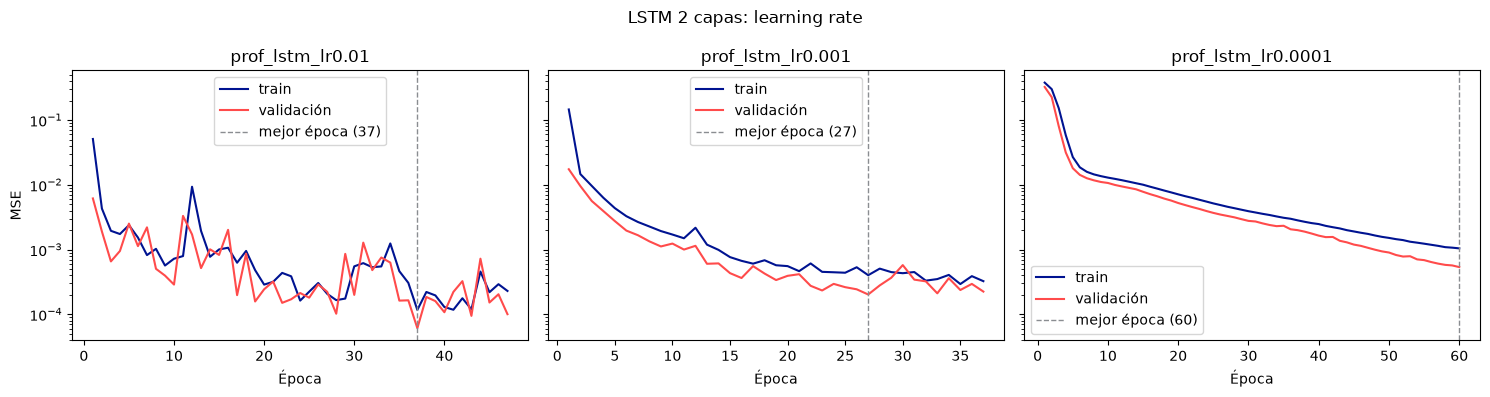

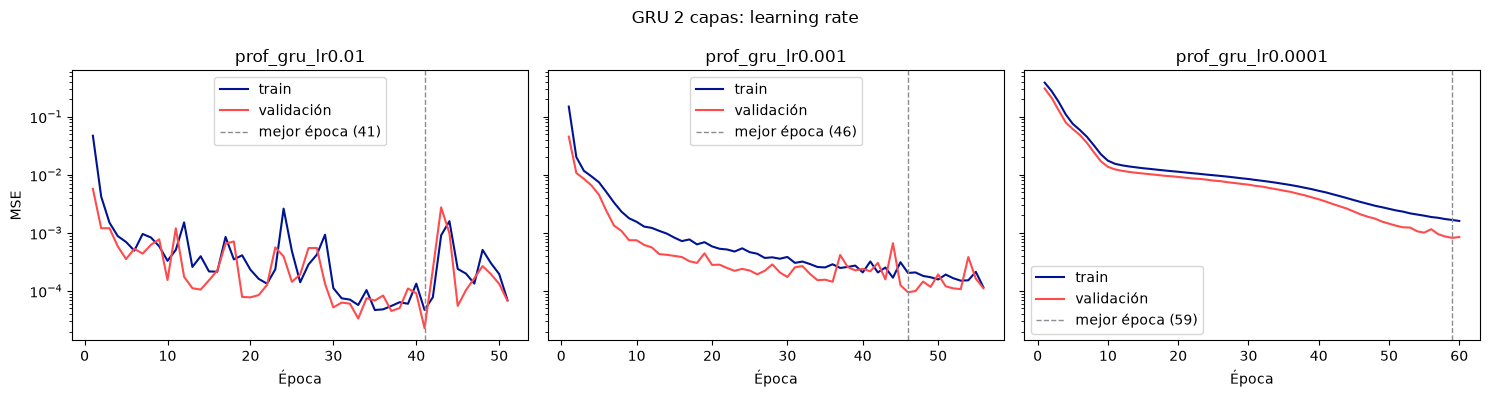

In [9]:
curvas([f"prof_lstm_lr{lr:g}" for lr in LRS], "LSTM 2 capas: learning rate")
curvas([f"prof_gru_lr{lr:g}" for lr in LRS], "GRU 2 capas: learning rate")

**Cómo leerlo.** Cada panel es un learning rate, de 0,01 a 0,0001. Con 0,01 el error llega más abajo, pero las curvas dan saltos grandes de una época a otra, en la LSTM y en la GRU. Con 0,001 son más suaves y acaban algo más arriba. Con 0,0001 bajan despacio y seguían bajando al llegar a las 60 épocas (mejor época 60 en la LSTM y 59 en la GRU).

#### 2.2 Dropout

In [10]:
filas = []
for tipo, lr in mejor_lr.items():
    for dropout in [0.0, 0.2]:
        torch.manual_seed(0)
        nombre = f"prof_{tipo.lower()}_lr{lr:g}" + (f"_do{dropout:g}" if dropout else "")
        filas.append(experimento(nombre, RedRecurrente(tipo, capas=2, dropout=dropout),
                                 epocas=60, lr=lr, paciencia=10))

tabla_dropout = pd.DataFrame(filas).set_index("modelo")
tabla_dropout.round(5)


prof_lstm_lr0.01
época   1 | train 0.05102 | val 0.00616
época   2 | train 0.00429 | val 0.00190
época   3 | train 0.00195 | val 0.00066
época   4 | train 0.00174 | val 0.00095
época   5 | train 0.00238 | val 0.00252
época   6 | train 0.00153 | val 0.00113
época   7 | train 0.00082 | val 0.00220
época   8 | train 0.00103 | val 0.00050
época   9 | train 0.00057 | val 0.00040
época  10 | train 0.00072 | val 0.00029
época  11 | train 0.00079 | val 0.00331
época  12 | train 0.00933 | val 0.00171
época  13 | train 0.00194 | val 0.00052
época  14 | train 0.00077 | val 0.00101
época  15 | train 0.00100 | val 0.00083
época  16 | train 0.00107 | val 0.00202
época  17 | train 0.00063 | val 0.00020
época  18 | train 0.00095 | val 0.00087
época  19 | train 0.00048 | val 0.00016
época  20 | train 0.00029 | val 0.00024
época  21 | train 0.00032 | val 0.00032
época  22 | train 0.00044 | val 0.00015
época  23 | train 0.00039 | val 0.00017
época  24 | train 0.00016 | val 0.00021
época  25 | train 0.00

,parámetros,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,
prof_lstm_lr0.01,13217,47,37,0.98571,0.00006,0.00490,0.99973
prof_lstm_lr0.01_do0.2,13217,31,21,0.79255,0.00021,0.00911,0.99906
prof_gru_lr0.01,9921,51,41,2.57982,0.00002,0.00325,0.99990
prof_gru_lr0.01_do0.2,9921,32,22,1.40937,0.00009,0.00609,0.99960


#### 2.3 Neuronas por capa

Cada capa recurrente tiene **32 neuronas**, que son la memoria de la red. Probamos **64** con el mejor learning rate y el mejor dropout de cada red: si con más memoria el error baja, se queda con 64.


In [11]:
mejor_do = {}
for tipo, lr in mejor_lr.items():
    base = f"prof_{tipo.lower()}_lr{lr:g}"
    mejor_do[tipo] = min([0.0, 0.2], key=lambda d: tabla_dropout.loc[base + (f"_do{d:g}" if d else ""), "MSE"])

filas = []
for tipo, lr in mejor_lr.items():
    for neuronas in [32, 64]:
        torch.manual_seed(0)
        nombre = (f"prof_{tipo.lower()}_lr{lr:g}" + (f"_do{mejor_do[tipo]:g}" if mejor_do[tipo] else "")
                  + ("_n64" if neuronas == 64 else ""))
        fila = experimento(nombre, RedRecurrente(tipo, capas=2, dropout=mejor_do[tipo], neuronas=neuronas),
                           epocas=60, lr=lr, paciencia=10)
        filas.append({**fila, "tipo": tipo, "neuronas": neuronas})

tabla_neuronas = pd.DataFrame(filas).set_index("modelo")
mejor_n = {tipo: int(tabla_neuronas[tabla_neuronas["tipo"] == tipo].sort_values("MSE")["neuronas"].iloc[0]) for tipo in mejor_lr}
print("Mejor dropout:", mejor_do, "| Mejores neuronas:", mejor_n)
tabla_neuronas.round(5)



prof_lstm_lr0.01
época   1 | train 0.05102 | val 0.00616
época   2 | train 0.00429 | val 0.00190
época   3 | train 0.00195 | val 0.00066
época   4 | train 0.00174 | val 0.00095
época   5 | train 0.00238 | val 0.00252
época   6 | train 0.00153 | val 0.00113
época   7 | train 0.00082 | val 0.00220
época   8 | train 0.00103 | val 0.00050
época   9 | train 0.00057 | val 0.00040
época  10 | train 0.00072 | val 0.00029
época  11 | train 0.00079 | val 0.00331
época  12 | train 0.00933 | val 0.00171
época  13 | train 0.00194 | val 0.00052
época  14 | train 0.00077 | val 0.00101
época  15 | train 0.00100 | val 0.00083
época  16 | train 0.00107 | val 0.00202
época  17 | train 0.00063 | val 0.00020
época  18 | train 0.00095 | val 0.00087
época  19 | train 0.00048 | val 0.00016
época  20 | train 0.00029 | val 0.00024
época  21 | train 0.00032 | val 0.00032
época  22 | train 0.00044 | val 0.00015
época  23 | train 0.00039 | val 0.00017
época  24 | train 0.00016 | val 0.00021
época  25 | train 0.00

,parámetros,épocas,mejor época,minutos,MSE,MAE,R²,tipo,neuronas
modelo,,,,,,,,,
prof_lstm_lr0.01,13217,47,37,0.91682,0.00006,0.00490,0.99973,LSTM,32
prof_lstm_lr0.01_n64,51009,41,31,1.30932,0.00008,0.00575,0.99966,LSTM,64
prof_gru_lr0.01,9921,51,41,2.06501,0.00002,0.00325,0.99990,GRU,32
prof_gru_lr0.01_n64,38273,42,32,2.45520,0.00002,0.00325,0.99991,GRU,64


#### 2.4 Modelo final: 100.000 simulaciones y test

La mejor configuración de cada red (learning rate, dropout y neuronas elegidos en validación) se entrena con las **100.000** simulaciones y se evalúa en **test**, que no se ha usado para elegir hiperparámetros.



final_lstm
época   1 | train 0.01312 | val 0.00154
época   2 | train 0.00107 | val 0.00106
época   3 | train 0.00068 | val 0.00061
época   4 | train 0.00075 | val 0.00039
época   5 | train 0.00067 | val 0.00041
época   6 | train 0.00062 | val 0.00015
época   7 | train 0.00041 | val 0.00033
época   8 | train 0.00022 | val 0.00034
época   9 | train 0.00099 | val 0.00166
época  10 | train 0.00035 | val 0.00100
época  11 | train 0.00050 | val 0.00016
época  12 | train 0.00026 | val 0.00011
época  13 | train 0.00025 | val 0.00011
época  14 | train 0.00024 | val 0.00016
época  15 | train 0.00066 | val 0.00015
época  16 | train 0.00018 | val 0.00104
época  17 | train 0.00048 | val 0.00017
época  18 | train 0.00014 | val 0.00014
época  19 | train 0.00027 | val 0.00008
época  20 | train 0.00036 | val 0.00008
época  21 | train 0.00030 | val 0.00031
época  22 | train 0.00013 | val 0.00005
época  23 | train 0.00015 | val 0.00004
época  24 | train 0.00018 | val 0.00017
época  25 | train 0.00061 | 

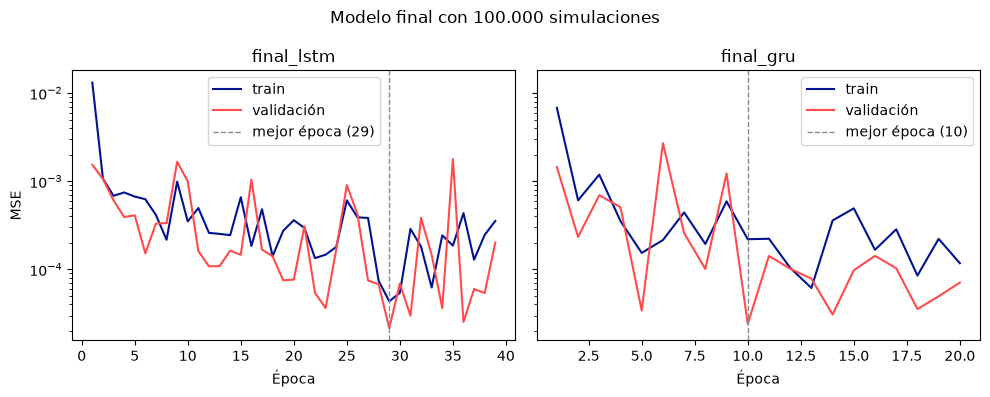

,parámetros,épocas,minutos,MSE test,MAE test,R² test
modelo,,,,,,
final_lstm,13217,39,3.70242,0.00002,0.00311,0.9999
final_gru,38273,20,5.49716,0.00002,0.00360,0.9999


In [12]:
dl_tr, dl_va, dl_te = repartir(len(X))

filas = []
for tipo, lr in mejor_lr.items():
    torch.manual_seed(0)
    red = RedRecurrente(tipo, capas=2, dropout=mejor_do[tipo], neuronas=mejor_n[tipo])
    fila = experimento(f"final_{tipo.lower()}", red, datos=(dl_tr, dl_va), epocas=60, lr=lr, paciencia=10)
    mse, pred, real = evaluar(red, dl_te)
    filas.append({"modelo": fila["modelo"], "parámetros": fila["parámetros"], "épocas": fila["épocas"],
                  "minutos": fila["minutos"], "MSE test": mse, "MAE test": abs(pred - real).mean(),
                  "R² test": 1 - mse / real.var()})

tabla_final = pd.DataFrame(filas).set_index("modelo")
curvas(["final_lstm", "final_gru"], "Modelo final con 100.000 simulaciones")
tabla_final.round(5)


**Cómo leerlo.** Son los modelos finales de la ronda 1, con las 100.000 simulaciones. La LSTM paró en la época 39 (mejor época 29) y la GRU en la 20 (mejor época 10), por la paciencia de 10 épocas. En las dos el error sube y baja de una época a otra, como con el learning rate de 0,01 de las pruebas anteriores.

---
# **BLOQUE 2, ronda 2**: rejillas ampliadas

La ronda 1 dejó cosas por resolver: el mejor learning rate (0,01) era el **más alto** de los probados, así que no sabíamos dónde está el óptimo, y las curvas con 0,01 daban saltos. Repetimos la búsqueda con estas reglas:

- **Épocas:** tope de **200** y paciencia **15**, para que cada configuración llegue hasta su mejor resultado y no la corte el límite.
- **Ganador acotado:** el valor ganador debe quedar **entre** los probados. Si cae en un extremo, se amplía la rejilla.
- **Empate:** si varias configuraciones quedan a menos de un **25 %** del mejor MSE, se elige la **más simple**. Con una sola semilla, diferencias más pequeñas son ruido.
- Los resultados de la ronda 1 se conservan arriba como registro de lo probado.

| Paso | Qué cambia | Valores |
|---|---|---|
| **R2.1** | Learning rate | 0,03 · 0,01 · 0,003 · 0,001 · 0,0001 |
| **R2.2** | Scheduler del learning rate | fijo · decaimiento 0,95 por época |
| **R2.3** | Capas recurrentes | 1 · 2 · 3 |
| **R2.4** | Dropout (solo con 2 capas o más) | 0 · 0,1 · 0,2 |
| **R2.5** | Neuronas por capa | 16 · 32 · 64 |
| **R2.6** | Modelo final con las **100.000** simulaciones y test | |
| **R2.7** | Comprobación extra: LSTM con learning rate alto y decaimiento | 0,01 con decaimiento 0,95 |
| **R2.8** | Robustez: el modelo final con varias semillas | 0 · 1 · 2 |

Cada paso usa el ganador del anterior y se elige con el error en **validación**.


In [13]:
EPOCAS, PACIENCIA, GAMMA, TOL = 200, 15, 0.95, 1.25   # TOL: empate = menos de un 25 % peor que el mejor MSE
TIPOS_BUSQUEDA = ["LSTM", "GRU"]


def nombre(tipo, lr, dec=None, capas=2, do=0.0, n=32):
    """Un nombre por configuración. Los valores por defecto no aparecen, así se reutilizan los entrenamientos ya hechos."""
    return (f"r2_{tipo.lower()}_lr{lr:g}" + ("_sch" if dec else "") + (f"_c{capas}" if capas != 2 else "")
            + (f"_do{do:g}" if do else "") + (f"_n{n}" if n != 32 else ""))


def probar(tipo, lr, dec=None, capas=2, do=0.0, n=32):
    torch.manual_seed(0)
    red = RedRecurrente(tipo, capas=capas, dropout=do, neuronas=n)
    fila = experimento(nombre(tipo, lr, dec, capas, do, n), red, epocas=EPOCAS, lr=lr, paciencia=PACIENCIA, decaimiento=dec)
    return {**fila, "tipo": tipo, "lr": lr, "decaimiento": dec, "capas": capas, "dropout": do, "neuronas": n}


def ganador(tabla, tipo, col, simple=True):
    """Valor de col de la mejor configuración. Con simple=True, entre las que empatan elige el valor más pequeño."""
    t = tabla[tabla["tipo"] == tipo]
    if simple:
        t = t[t["MSE"] <= TOL * t["MSE"].min()]
        return t.sort_values(col)[col].iloc[0].item()
    return t.sort_values("MSE")[col].iloc[0].item()


def extremo(gan, valores):
    return {t: v in (min(valores), max(valores)) for t, v in gan.items()}


COLS = ["tipo", "épocas", "mejor época", "minutos", "MSE", "MAE", "R²"]


#### R2.1 Learning rate

Cinco valores con 2 capas, sin dropout y sin scheduler. El ganador debe quedar en medio: si gana 0,03 o 0,0001, ampliamos.


In [14]:
LRS2 = [3e-2, 1e-2, 3e-3, 1e-3, 1e-4]

t_lr = pd.DataFrame([probar(t, lr) for t in TIPOS_BUSQUEDA for lr in LRS2]).set_index("modelo")
gan_lr = {t: ganador(t_lr, t, "lr", simple=False) for t in TIPOS_BUSQUEDA}
print("Mejor learning rate:", gan_lr, "| en un extremo:", extremo(gan_lr, LRS2))
t_lr[COLS[:1] + ["lr"] + COLS[1:]].round(5)



r2_lstm_lr0.03
época   1 | train 0.10227 | val 0.00887
época   2 | train 0.00484 | val 0.00170
época   3 | train 0.00164 | val 0.00137
época   4 | train 0.00153 | val 0.00106
época   5 | train 0.00126 | val 0.00167
época   6 | train 0.00290 | val 0.00337
época   7 | train 0.00236 | val 0.00140
época   8 | train 0.00380 | val 0.00386
época   9 | train 0.00209 | val 0.00075
época  10 | train 0.00084 | val 0.00077
época  11 | train 0.00076 | val 0.00116
época  12 | train 0.00214 | val 0.00075
época  13 | train 0.00124 | val 0.00046
época  14 | train 0.00139 | val 0.00489
época  15 | train 0.00093 | val 0.00020
época  16 | train 0.00041 | val 0.00160
época  17 | train 0.00075 | val 0.00033
época  18 | train 0.00120 | val 0.00127
época  19 | train 0.00405 | val 0.00200
época  20 | train 0.00169 | val 0.00065
época  21 | train 0.00033 | val 0.00088
época  22 | train 0.00087 | val 0.00022
época  23 | train 0.00038 | val 0.00017
época  24 | train 0.00017 | val 0.00030
época  25 | train 0.0001

,tipo,lr,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,,
r2_lstm_lr0.03,LSTM,0.0300,46,31,1.09778,0.00007,0.00582,0.99969
r2_lstm_lr0.01,LSTM,0.0100,52,37,1.07435,0.00006,0.00490,0.99973
r2_lstm_lr0.003,LSTM,0.0030,33,18,0.65489,0.00016,0.00822,0.99930
r2_lstm_lr0.001,LSTM,0.0010,151,136,2.97950,0.00002,0.00331,0.99989
r2_lstm_lr0.0001,LSTM,0.0001,200,198,3.91832,0.00009,0.00650,0.99958
r2_gru_lr0.03,GRU,0.0300,42,27,1.70926,0.00005,0.00410,0.99980
r2_gru_lr0.01,GRU,0.0100,56,41,2.25243,0.00002,0.00325,0.99990
r2_gru_lr0.003,GRU,0.0030,49,34,2.03518,0.00005,0.00511,0.99978
r2_gru_lr0.001,GRU,0.0010,92,77,3.77122,0.00004,0.00476,0.99980


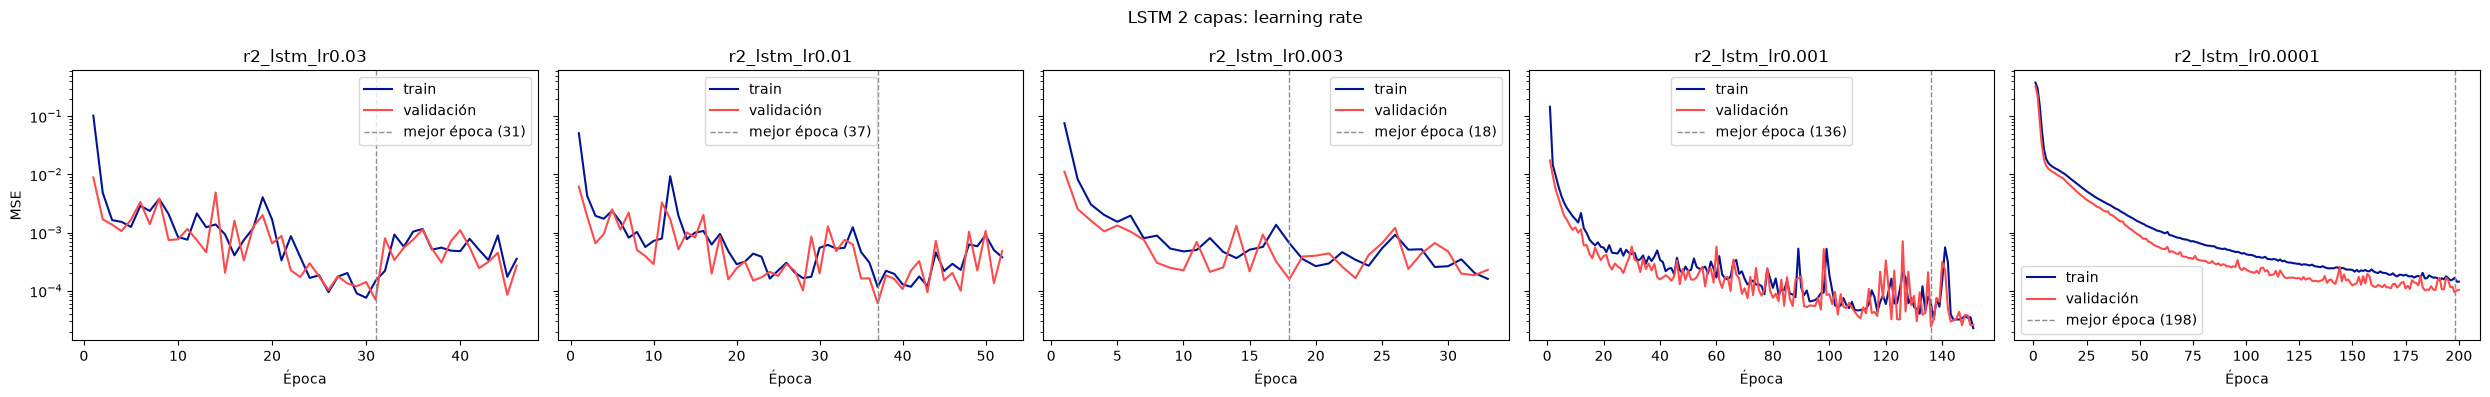

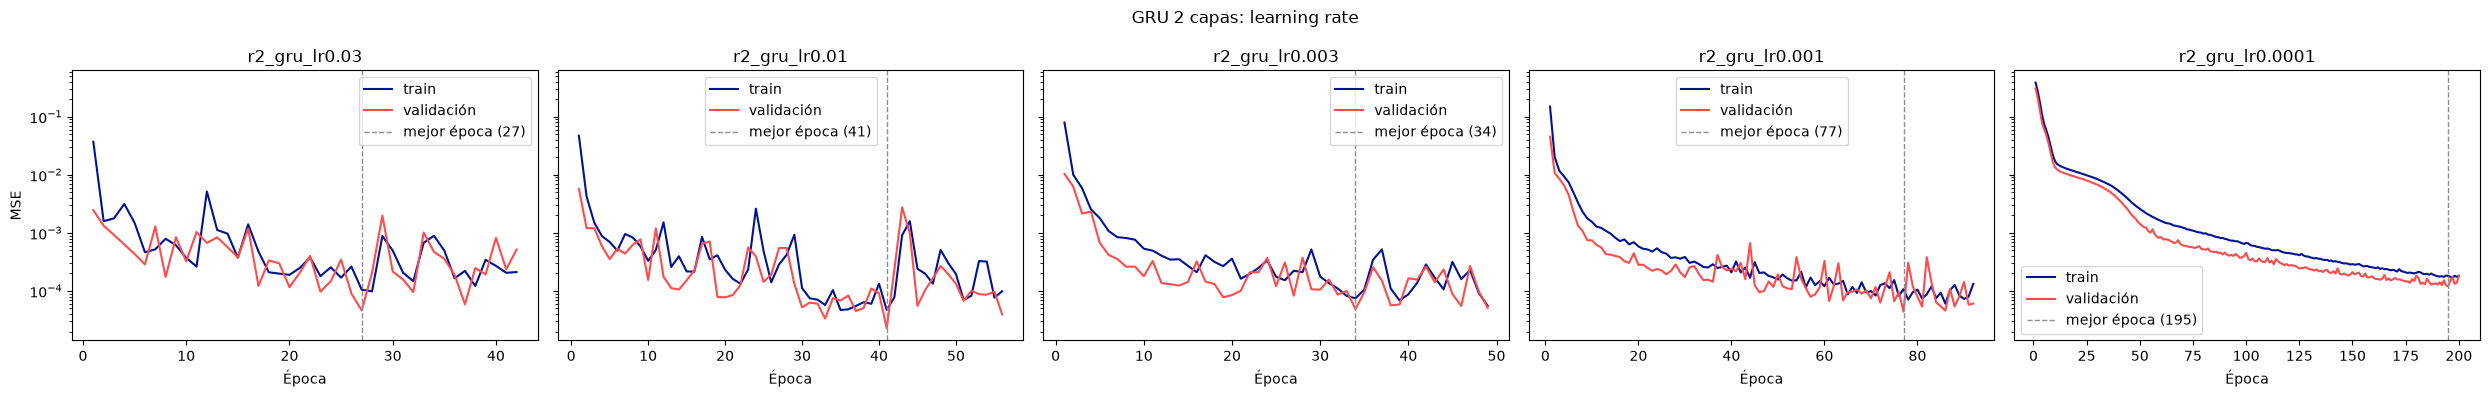

In [15]:
for t in TIPOS_BUSQUEDA:
    curvas([nombre(t, lr) for lr in LRS2], f"{t} 2 capas: learning rate")


**Cómo leerlo.** Una fila por red, con cinco learning rates de 0,03 a 0,0001. Con 0,03 y 0,01 las curvas son las más irregulares. Con 0,0001 son lisas, pero bajan tan despacio que llegan al tope de 200 épocas sin parar (mejor época 198 en la LSTM y 195 en la GRU). Los ganadores quedan dentro de la rejilla: 0,001 en la LSTM y 0,01 en la GRU.

#### R2.2 Scheduler del learning rate

Con el mejor learning rate de cada red, comparamos dejarlo **fijo** con **decaimiento 0,95** por época. Si el decaimiento baja el error, se queda. Mira también las curvas: tienen que dar menos saltos.



r2_lstm_lr0.001
época   1 | train 0.14587 | val 0.01740
época   2 | train 0.01466 | val 0.00959
época   3 | train 0.00960 | val 0.00561
época   4 | train 0.00631 | val 0.00393
época   5 | train 0.00436 | val 0.00275
época   6 | train 0.00327 | val 0.00196
época   7 | train 0.00266 | val 0.00167
época   8 | train 0.00227 | val 0.00134
época   9 | train 0.00193 | val 0.00112
época  10 | train 0.00171 | val 0.00124
época  11 | train 0.00149 | val 0.00100
época  12 | train 0.00217 | val 0.00114
época  13 | train 0.00119 | val 0.00060
época  14 | train 0.00099 | val 0.00061
época  15 | train 0.00076 | val 0.00043
época  16 | train 0.00067 | val 0.00036
época  17 | train 0.00061 | val 0.00055
época  18 | train 0.00068 | val 0.00043
época  19 | train 0.00057 | val 0.00034
época  20 | train 0.00055 | val 0.00039
época  21 | train 0.00046 | val 0.00042
época  22 | train 0.00061 | val 0.00028
época  23 | train 0.00045 | val 0.00023
época  24 | train 0.00045 | val 0.00029
época  25 | train 0.000

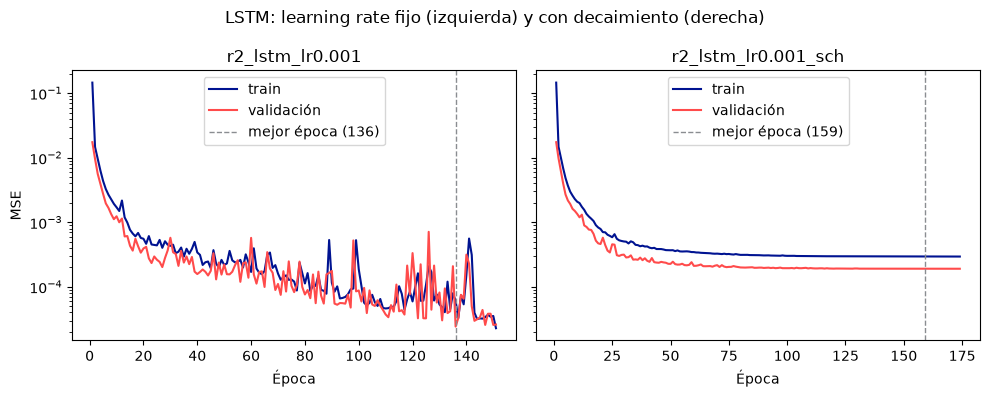

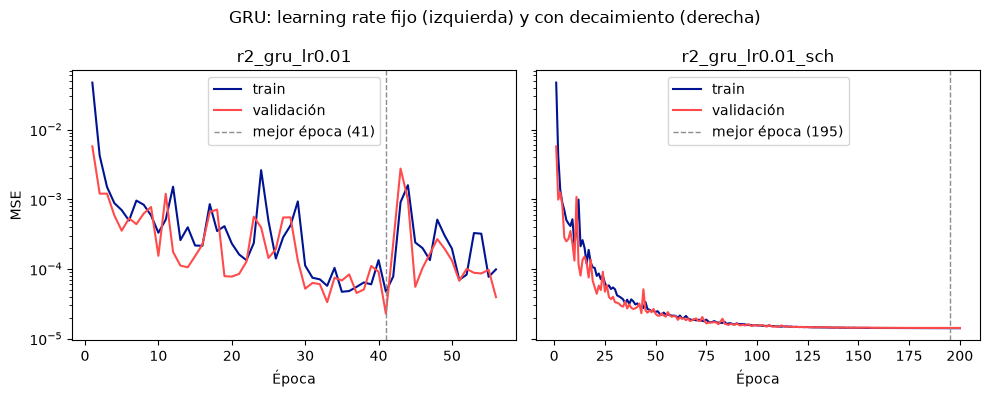

,tipo,lr,decaimiento,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,,,
r2_lstm_lr0.001,LSTM,0.001,NaN,151,136,3.25086,0.00002,0.00331,0.99989
r2_lstm_lr0.001_sch,LSTM,0.001,0.95,174,159,3.45400,0.00019,0.00976,0.99916
r2_gru_lr0.01,GRU,0.010,NaN,56,41,2.31139,0.00002,0.00325,0.99990
r2_gru_lr0.01_sch,GRU,0.010,0.95,200,195,8.20900,0.00001,0.00262,0.99994


In [16]:
t_sch = pd.DataFrame([probar(t, gan_lr[t], dec) for t in TIPOS_BUSQUEDA for dec in (None, GAMMA)]).set_index("modelo")
gan_dec = {t: GAMMA if t_sch.loc[nombre(t, gan_lr[t], GAMMA), "MSE"] < t_sch.loc[nombre(t, gan_lr[t]), "MSE"] else None
           for t in TIPOS_BUSQUEDA}
print("Decaimiento elegido:", gan_dec)
for t in TIPOS_BUSQUEDA:
    curvas([nombre(t, gan_lr[t]), nombre(t, gan_lr[t], GAMMA)], f"{t}: learning rate fijo (izquierda) y con decaimiento (derecha)")
t_sch[COLS[:1] + ["lr", "decaimiento"] + COLS[1:]].round(5)


**Cómo leerlo.** A la izquierda, learning rate fijo; a la derecha, con decaimiento de 0,95 por época. En la GRU el decaimiento quita los saltos y baja el error hasta unos 0,00001. En la LSTM, con su learning rate de 0,001, el error se aplana pronto, en torno a 0,0002, porque el learning rate se encoge antes de que la red termine de afinar.

#### R2.3 Capas recurrentes

1, 2 y 3 capas apiladas, con el mejor learning rate y decaimiento. En la ronda 1 la LSTM de 1 y de 2 capas dieron el mismo error con learning rate 0,001, así que aquí se comprueba de verdad si la profundidad sirve.


In [17]:
CAPAS = [1, 2, 3]

t_capas = pd.DataFrame([probar(t, gan_lr[t], gan_dec[t], capas=c) for t in TIPOS_BUSQUEDA for c in CAPAS]).set_index("modelo")
gan_capas = {t: ganador(t_capas, t, "capas") for t in TIPOS_BUSQUEDA}
print("Capas elegidas:", gan_capas, "| en un extremo:", extremo(gan_capas, CAPAS))
t_capas[COLS[:1] + ["capas"] + COLS[1:]].round(5)



r2_lstm_lr0.001_c1
época   1 | train 0.15265 | val 0.02886
época   2 | train 0.01931 | val 0.01173
época   3 | train 0.01138 | val 0.00631
época   4 | train 0.00659 | val 0.00316
época   5 | train 0.00387 | val 0.00170
época   6 | train 0.00267 | val 0.00124
época   7 | train 0.00210 | val 0.00101
época   8 | train 0.00181 | val 0.00104
época   9 | train 0.00156 | val 0.00073
época  10 | train 0.00133 | val 0.00082
época  11 | train 0.00124 | val 0.00090
época  12 | train 0.00118 | val 0.00072
época  13 | train 0.00102 | val 0.00080
época  14 | train 0.00088 | val 0.00045
época  15 | train 0.00085 | val 0.00044
época  16 | train 0.00077 | val 0.00055
época  17 | train 0.00075 | val 0.00038
época  18 | train 0.00069 | val 0.00034
época  19 | train 0.00060 | val 0.00040
época  20 | train 0.00058 | val 0.00031
época  21 | train 0.00055 | val 0.00030
época  22 | train 0.00050 | val 0.00030
época  23 | train 0.00047 | val 0.00028
época  24 | train 0.00048 | val 0.00026
época  25 | train 0.

,tipo,capas,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,,
r2_lstm_lr0.001_c1,LSTM,1,135,120,1.73294,0.00004,0.00433,0.99983
r2_lstm_lr0.001,LSTM,2,151,136,2.96547,0.00002,0.00331,0.99989
r2_lstm_lr0.001_c3,LSTM,3,51,36,1.38003,0.00012,0.00739,0.99945
r2_gru_lr0.01_sch_c1,GRU,1,183,168,4.22603,0.00004,0.00436,0.99984
r2_gru_lr0.01_sch,GRU,2,200,195,8.13573,0.00001,0.00262,0.99994
r2_gru_lr0.01_sch_c3,GRU,3,177,162,10.39148,0.00001,0.00231,0.99994


#### R2.4 Dropout

0, 0,1 y 0,2 entre capas recurrentes. Solo tiene efecto con 2 capas o más: si gana 1 capa, se prueba solo el 0.


In [18]:
DROPOUTS = [0.0, 0.1, 0.2]

t_do = pd.DataFrame([probar(t, gan_lr[t], gan_dec[t], capas=gan_capas[t], do=d)
                     for t in TIPOS_BUSQUEDA for d in (DROPOUTS if gan_capas[t] > 1 else [0.0])]).set_index("modelo")
gan_do = {t: ganador(t_do, t, "dropout") for t in TIPOS_BUSQUEDA}
print("Dropout elegido:", gan_do)
t_do[COLS[:1] + ["dropout"] + COLS[1:]].round(5)



r2_lstm_lr0.001
época   1 | train 0.14587 | val 0.01740
época   2 | train 0.01466 | val 0.00959
época   3 | train 0.00960 | val 0.00561
época   4 | train 0.00631 | val 0.00393
época   5 | train 0.00436 | val 0.00275
época   6 | train 0.00327 | val 0.00196
época   7 | train 0.00266 | val 0.00167
época   8 | train 0.00227 | val 0.00134
época   9 | train 0.00193 | val 0.00112
época  10 | train 0.00171 | val 0.00124
época  11 | train 0.00149 | val 0.00100
época  12 | train 0.00217 | val 0.00114
época  13 | train 0.00119 | val 0.00060
época  14 | train 0.00099 | val 0.00061
época  15 | train 0.00076 | val 0.00043
época  16 | train 0.00067 | val 0.00036
época  17 | train 0.00061 | val 0.00055
época  18 | train 0.00068 | val 0.00043
época  19 | train 0.00057 | val 0.00034
época  20 | train 0.00055 | val 0.00039
época  21 | train 0.00046 | val 0.00042
época  22 | train 0.00061 | val 0.00028
época  23 | train 0.00045 | val 0.00023
época  24 | train 0.00045 | val 0.00029
época  25 | train 0.000

,tipo,dropout,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,,
r2_lstm_lr0.001,LSTM,0.0,151,136,3.03632,0.00002,0.00331,0.99989
r2_lstm_lr0.001_do0.1,LSTM,0.1,156,141,3.65785,0.00006,0.00516,0.99972
r2_lstm_lr0.001_do0.2,LSTM,0.2,70,55,1.65188,0.00013,0.00738,0.99943
r2_gru_lr0.01_sch,GRU,0.0,200,195,8.14247,0.00001,0.00262,0.99994
r2_gru_lr0.01_sch_do0.1,GRU,0.1,104,89,4.59846,0.00003,0.00351,0.99988
r2_gru_lr0.01_sch_do0.2,GRU,0.2,77,62,3.36998,0.00005,0.00473,0.99979


#### R2.5 Neuronas por capa

16, 32 y 64. Si con 16 el error es casi el mismo, nos quedamos con la red más pequeña.


In [19]:
NEURONAS = [16, 32, 64]

t_n = pd.DataFrame([probar(t, gan_lr[t], gan_dec[t], gan_capas[t], gan_do[t], n)
                    for t in TIPOS_BUSQUEDA for n in NEURONAS]).set_index("modelo")
gan_n = {t: ganador(t_n, t, "neuronas") for t in TIPOS_BUSQUEDA}
print("Neuronas elegidas:", gan_n, "| en un extremo:", extremo(gan_n, NEURONAS))
t_n[COLS[:1] + ["neuronas", "parámetros"] + COLS[1:]].round(5)



r2_lstm_lr0.001_n16
época   1 | train 0.27645 | val 0.09616
época   2 | train 0.03992 | val 0.01681
época   3 | train 0.01613 | val 0.00974
época   4 | train 0.01089 | val 0.00627
época   5 | train 0.00832 | val 0.00467
época   6 | train 0.00661 | val 0.00355
época   7 | train 0.00533 | val 0.00298
época   8 | train 0.00432 | val 0.00216
época   9 | train 0.00355 | val 0.00175
época  10 | train 0.00307 | val 0.00141
época  11 | train 0.00280 | val 0.00113
época  12 | train 0.00232 | val 0.00121
época  13 | train 0.00207 | val 0.00117
época  14 | train 0.00179 | val 0.00074
época  15 | train 0.00165 | val 0.00075
época  16 | train 0.00161 | val 0.00058
época  17 | train 0.00143 | val 0.00056
época  18 | train 0.00123 | val 0.00060
época  19 | train 0.00120 | val 0.00051
época  20 | train 0.00110 | val 0.00046
época  21 | train 0.00105 | val 0.00061
época  22 | train 0.00096 | val 0.00047
época  23 | train 0.00091 | val 0.00042
época  24 | train 0.00085 | val 0.00045
época  25 | train 0

,tipo,neuronas,parámetros,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,,,,
r2_lstm_lr0.001_n16,LSTM,16,3537,200,187,3.12927,0.00004,0.00413,0.99982
r2_lstm_lr0.001,LSTM,32,13217,151,136,3.03280,0.00002,0.00331,0.99989
r2_lstm_lr0.001_n64,LSTM,64,51009,64,49,2.06339,0.00004,0.00443,0.99982
r2_gru_lr0.01_sch_n16,GRU,16,2657,170,155,5.62843,0.00004,0.00431,0.99983
r2_gru_lr0.01_sch,GRU,32,9921,200,195,8.21714,0.00001,0.00262,0.99994
r2_gru_lr0.01_sch_n64,GRU,64,38273,200,188,12.38816,0.00001,0.00174,0.99997


#### R2.6 Modelo final: 100.000 simulaciones y test

La mejor configuración de cada red se entrena con las **100.000** simulaciones y se evalúa en **test**, que no se ha usado para elegir hiperparámetros, con el mismo reparto que el modelo final de la ronda 1 para poder compararlos.



r2_final_lstm
época   1 | train 0.03465 | val 0.00418
época   2 | train 0.00207 | val 0.00192
época   3 | train 0.00103 | val 0.00108
época   4 | train 0.00053 | val 0.00094
época   5 | train 0.00047 | val 0.00059
época   6 | train 0.00037 | val 0.00053
época   7 | train 0.00033 | val 0.00091
época   8 | train 0.00033 | val 0.00038
época   9 | train 0.00034 | val 0.00038
época  10 | train 0.00023 | val 0.00092
época  11 | train 0.00023 | val 0.00024
época  12 | train 0.00019 | val 0.00019
época  13 | train 0.00018 | val 0.00023
época  14 | train 0.00018 | val 0.00013
época  15 | train 0.00019 | val 0.00038
época  16 | train 0.00018 | val 0.00022
época  17 | train 0.00013 | val 0.00027
época  18 | train 0.00014 | val 0.00010
época  19 | train 0.00015 | val 0.00018
época  20 | train 0.00008 | val 0.00017
época  21 | train 0.00017 | val 0.00015
época  22 | train 0.00007 | val 0.00007
época  23 | train 0.00007 | val 0.00005
época  24 | train 0.00011 | val 0.00009
época  25 | train 0.00010

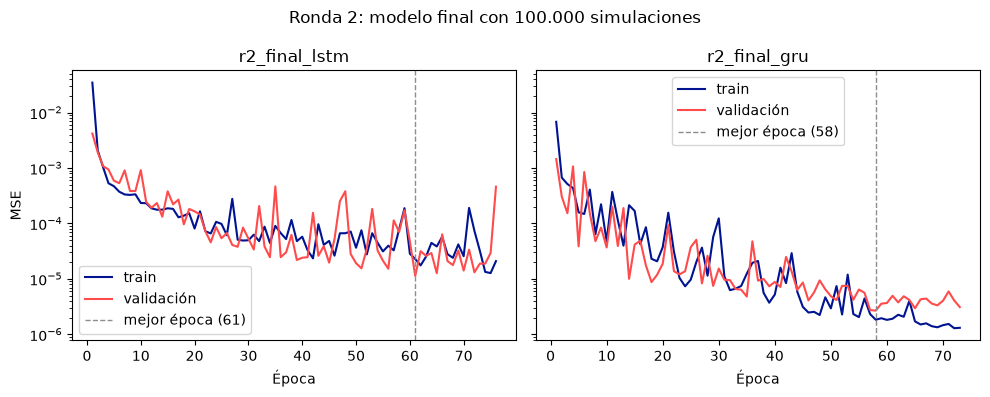

,configuración,parámetros,épocas,minutos,MSE test,MAE test,R² test
modelo,,,,,,,
r2_final_lstm,"lr 0.001, decaimiento None, 2 capas, dropout 0...",13217,76,7.48783,0.00001,0.00214,0.99995
r2_final_gru,"lr 0.01, decaimiento 0.95, 2 capas, dropout 0,...",38273,73,22.14940,0.00000,0.00079,0.99999


In [20]:
dl_tr, dl_va, dl_te = repartir(len(X))

filas = []
for t in TIPOS_BUSQUEDA:
    torch.manual_seed(0)
    red = RedRecurrente(t, capas=gan_capas[t], dropout=gan_do[t], neuronas=gan_n[t])
    fila = experimento(f"r2_final_{t.lower()}", red, datos=(dl_tr, dl_va), epocas=EPOCAS, lr=gan_lr[t],
                       paciencia=PACIENCIA, decaimiento=gan_dec[t])
    mse, pred, real = evaluar(red, dl_te)
    filas.append({"modelo": fila["modelo"],
                  "configuración": f"lr {gan_lr[t]:g}, decaimiento {gan_dec[t]}, {gan_capas[t]} capas, dropout {gan_do[t]:g}, {gan_n[t]} neuronas",
                  "parámetros": fila["parámetros"], "épocas": fila["épocas"], "minutos": fila["minutos"],
                  "MSE test": mse, "MAE test": abs(pred - real).mean(), "R² test": 1 - mse / real.var()})

t_final = pd.DataFrame(filas).set_index("modelo")
curvas(["r2_final_lstm", "r2_final_gru"], "Ronda 2: modelo final con 100.000 simulaciones")
t_final.round(5)


**Cómo leerlo.** Son los modelos finales de la ronda 2, con las 100.000 simulaciones. La LSTM, con learning rate fijo, sigue dando picos hasta el final (mejor época 61, paró en la 76). La GRU, con decaimiento, se calma y mejora hasta la época 58; su error en validación queda algo por encima del de train, con los dos por debajo de 0,00001.

#### R2.7 Comprobación extra: LSTM con learning rate alto y decaimiento

En R2.2 el decaimiento se probó con el learning rate ganador de cada red. En la LSTM era **0,001**, que ya es bajo: con decaimiento 0,95 por época baja a unos 0,00008 en la época 50 y a 0,000006 en la 100, y la red **deja de aprender** antes de afinar. El decaimiento está pensado para empezar **alto** y terminar bajo, como en la GRU.

Aquí la LSTM empieza en **0,01** con decaimiento y se compara con su mejor configuración de R2.1 a R2.5. Si baja el error, hay que reentrenar su modelo final con esta configuración.



r2_lstm_lr0.01_sch
época   1 | train 0.05102 | val 0.00616
época   2 | train 0.00437 | val 0.00255
época   3 | train 0.00220 | val 0.00051
época   4 | train 0.00135 | val 0.00055
época   5 | train 0.00114 | val 0.00043
época   6 | train 0.00101 | val 0.00139
época   7 | train 0.00088 | val 0.00056
época   8 | train 0.00092 | val 0.00046
época   9 | train 0.00052 | val 0.00027
época  10 | train 0.00054 | val 0.00045
época  11 | train 0.00054 | val 0.00037
época  12 | train 0.00098 | val 0.00022
época  13 | train 0.00039 | val 0.00020
época  14 | train 0.00036 | val 0.00038
época  15 | train 0.00058 | val 0.00030
época  16 | train 0.00027 | val 0.00051
época  17 | train 0.00035 | val 0.00016
época  18 | train 0.00066 | val 0.00014
época  19 | train 0.00020 | val 0.00019
época  20 | train 0.00016 | val 0.00014
época  21 | train 0.00017 | val 0.00056
época  22 | train 0.00037 | val 0.00017
época  23 | train 0.00020 | val 0.00011
época  24 | train 0.00016 | val 0.00017
época  25 | train 0.

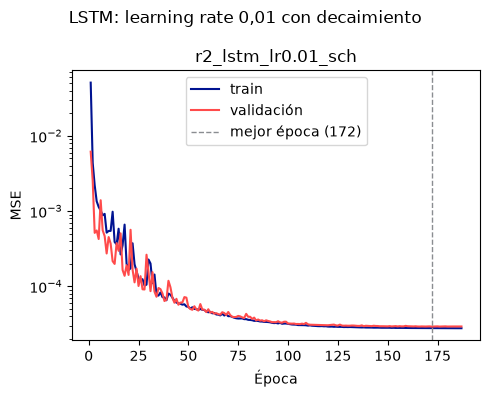

,épocas,mejor época,minutos,MSE,MAE,R²
modelo,,,,,,
r2_lstm_lr0.01_sch,187,172,3.735132,0.000029,0.003366,0.999871


In [21]:
t_lstm_sch = pd.DataFrame([probar("LSTM", 0.01, GAMMA)]).set_index("modelo")
print("MSE de la mejor LSTM de la ronda 2:", round(t_lr.loc[nombre("LSTM", gan_lr["LSTM"]), "MSE"], 8))
print("MSE de la LSTM con lr 0,01 y decaimiento:", round(t_lstm_sch["MSE"].iloc[0], 8))
curvas(["r2_lstm_lr0.01_sch"], "LSTM: learning rate 0,01 con decaimiento")
t_lstm_sch[["épocas", "mejor época", "minutos", "MSE", "MAE", "R²"]].round(8)


**Cómo leerlo.** La LSTM con learning rate de 0,01 y decaimiento baja sin saltos y se estanca en torno a 0,00003 a partir de la época 100 (mejor época 172). No mejora a la LSTM con learning rate fijo (0,00002), así que se mantiene esa configuración.

#### R2.8 Robustez: el modelo final con varias semillas

Hasta ahora cada configuración se ha entrenado **una sola vez**, y con errores tan pequeños, dos entrenamientos de la misma configuración pueden diferir por la inicialización al azar. Aquí se entrena el **modelo final de cada red con 3 semillas** (la 0 ya está hecha en R2.6) y se da el resultado en test como **media y desviación**.

Si la diferencia entre la LSTM y la GRU es menor que la desviación entre semillas, la conclusión es que **empatan**.


In [22]:
SEMILLAS = [0, 1, 2]


def final_con_semilla(t, semilla):
    torch.manual_seed(semilla)
    red = RedRecurrente(t, capas=gan_capas[t], dropout=gan_do[t], neuronas=gan_n[t])
    nom = f"r2_final_{t.lower()}" + (f"_s{semilla}" if semilla else "")
    experimento(nom, red, datos=(dl_tr, dl_va), epocas=EPOCAS, lr=gan_lr[t], paciencia=PACIENCIA, decaimiento=gan_dec[t])
    mse, pred, real = evaluar(red, dl_te)
    return {"tipo": t, "semilla": semilla, "MSE test": mse, "MAE test": abs(pred - real).mean(), "R² test": 1 - mse / real.var()}


t_semillas = pd.DataFrame([final_con_semilla(t, s) for t in TIPOS_BUSQUEDA for s in SEMILLAS])
print(t_semillas.round(8).to_string(index=False))
t_semillas.groupby("tipo")[["MSE test", "MAE test", "R² test"]].agg(["mean", "std"]).round(8)



r2_final_lstm
época   1 | train 0.03465 | val 0.00418
época   2 | train 0.00207 | val 0.00192
época   3 | train 0.00103 | val 0.00108
época   4 | train 0.00053 | val 0.00094
época   5 | train 0.00047 | val 0.00059
época   6 | train 0.00037 | val 0.00053
época   7 | train 0.00033 | val 0.00091
época   8 | train 0.00033 | val 0.00038
época   9 | train 0.00034 | val 0.00038
época  10 | train 0.00023 | val 0.00092
época  11 | train 0.00023 | val 0.00024
época  12 | train 0.00019 | val 0.00019
época  13 | train 0.00018 | val 0.00023
época  14 | train 0.00018 | val 0.00013
época  15 | train 0.00019 | val 0.00038
época  16 | train 0.00018 | val 0.00022
época  17 | train 0.00013 | val 0.00027
época  18 | train 0.00014 | val 0.00010
época  19 | train 0.00015 | val 0.00018
época  20 | train 0.00008 | val 0.00017
época  21 | train 0.00017 | val 0.00015
época  22 | train 0.00007 | val 0.00007
época  23 | train 0.00007 | val 0.00005
época  24 | train 0.00011 | val 0.00009
época  25 | train 0.00010

MSE test                MAE test             R² test              
          mean           std      mean       std      mean           std
tipo                                                                    
GRU   0.000002  2.100000e-07  0.000796  0.000012  0.999989  9.000000e-07
LSTM  0.000009  3.390000e-06  0.001720  0.000379  0.999961  1.461000e-05

#### Conclusiones del bloque 2

La mejor red es la **GRU**. En test, con las 100.000 simulaciones y tres semillas, se equivoca de media **0,0008** en el payoff (MAE, desviación 0,00001), frente a **0,0017** de la LSTM (desviación 0,0004). La peor GRU (0,00081) es mejor que la mejor LSTM (0,00140), así que la diferencia no depende de la semilla. En igualdad de condiciones (2 capas, 32 neuronas, learning rate 0,01 con decaimiento 0,95) también gana: MSE en validación de 0,0000143 contra 0,0000291.

Frente a la red base, el MSE en validación de la LSTM baja de 0,00020 a 0,000024, y el de la GRU de 0,00026 a 0,000014 (con 32 neuronas).

- **Learning rate:** da la mayor parte de la mejora, junto con dejar más épocas. Entre 0,001 y 0,03 todas las pruebas funcionan; los mejores fueron 0,001 para la LSTM y 0,01 para la GRU. No se puede fijar un óptimo exacto: la LSTM sale peor con 0,003 que con sus dos vecinos, y ese entrenamiento paró en la época 33 por la paciencia, así que lo tomamos como ruido de una sola semilla.
- **Dropout:** con 0 el error es el menor en las dos redes y sube cada vez que se sube el dropout (LSTM 0,00002, 0,00006 y 0,00013 con 0, 0,1 y 0,2; GRU 0,00001, 0,00003 y 0,00005). Train y validación van juntas, no hay sobreajuste que corregir.
- **Scheduler:** ayuda a la GRU (0,00001 contra 0,00002) y no a la LSTM. Con su learning rate de 0,001, el decaimiento la frena antes de afinar (0,00019); empezando en 0,01 se estanca en 0,00003. La LSTM final va con learning rate fijo, y por eso sus curvas tienen picos hasta el final mientras las de la GRU se calman.
- **Tamaño:** 2 capas en las dos (la LSTM de 1 capa llega a 0,00004 y la de 2 a 0,00002). La LSTM se queda en 32 neuronas (con 16 y con 64 el error se duplica) y la GRU en 64. Esa GRU tiene 38.273 parámetros y tarda unos 22 minutos con 100.000 simulaciones; la LSTM tiene 13.217 y tarda unos 9.

Hay límites que conviene tener presentes. La GRU gana con 64 neuronas, el extremo de la rejilla, y no probamos 128. No exploramos el batch, el weight decay ni la RNN simple con learning rate alto, que se descartó con el learning rate de la base. Son tres semillas, todas con el mismo reparto de datos.

Con la trayectoria completa, el payoff es una función exacta de los precios, así que un R² de 0,9999 era esperable y no demuestra que la red sirva para valorar. Esa prueba está en el bloque 3 y en resultados.ipynb, donde la prima de las redes se compara con la del Montecarlo. La GRU es el modelo principal y la LSTM la comparación.


---
# **BLOQUE 3**: la red con trayectorias cortadas

Hasta ahora la red ha visto siempre trayectorias **completas** (hasta T20). Aquí tomamos la **mejor LSTM** y la **mejor GRU**, **sin reentrenarlas**, y en test les damos trayectorias **cortadas por el final**: solo hasta **T19, T18, T17 o T16**. Tienen que predecir igualmente el **payoff de T20**.

- Es como valorar la opción en ese trimestre, cuando todavía **no se sabe** cómo acaban los precios.
- Una red recurrente puede leer secuencias más cortas sin cambiar nada.
- Medimos el error según **cuántos trimestres faltan** (0, 1, 2, 3 y 4).
- Calculamos la **prima** que da la red con cada corte, de 1 a 20 trimestres vistos, y la comparamos con el Montecarlo de esas 10.000 simulaciones.

Lo esperable es que el error **suba** cuantos más trimestres falten, porque la red nunca ha entrenado con trayectorias incompletas.

In [23]:
MU, T = 0.01, 5                      # tasa libre de riesgo y años, como en montecarlo.ipynb
DESC = np.exp(-MU * T)               # descuento de T20 a t0 (0,9512)

# Mejores LSTM y GRU (modelos finales de la ronda 2, 3 semillas), sin reentrenar.
# dl_te es el test del reparto de 100.000 simulaciones (10.000 trayectorias).
def cargar_final(tipo, semilla):
    red = RedRecurrente(tipo, capas=gan_capas[tipo], dropout=gan_do[tipo], neuronas=gan_n[tipo])
    nom = f"r2_final_{tipo.lower()}" + (f"_s{semilla}" if semilla else "")
    red.load_state_dict(torch.load(f"modelos/{nom}.pt"))
    return red.eval()


x_te, y_te = dl_te.dataset.tensors
y_te = y_te.squeeze(-1).numpy()                 # payoff real de T20
CORTES = [20, 19, 18, 17, 16]                   # trimestres que ve la red

filas = []
for tipo in TIPOS_BUSQUEDA:
    for s in SEMILLAS:
        red = cargar_final(tipo, s)
        with torch.no_grad():
            for largo in CORTES:
                err = red(x_te[:, :largo]).squeeze(-1).numpy() - y_te
                filas.append({"red": tipo, "semilla": s, "faltan": 20 - largo,
                              "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "sesgo": err.mean()})

res3 = pd.DataFrame(filas)
print(f"RMSE de predecir siempre la media: {y_te.std():.4f}")
tabla3 = res3.groupby(["red", "faltan"])[["MAE", "RMSE", "sesgo"]].mean().unstack("red")
tabla3.round(5)

RMSE de predecir siempre la media: 0.4817


MAE              RMSE             sesgo         
red         GRU     LSTM      GRU     LSTM      GRU     LSTM
faltan                                                      
0       0.00080  0.00172  0.00156  0.00299  0.00016  0.00042
1       0.02483  0.02918  0.04678  0.05724 -0.00894 -0.01390
2       0.04878  0.05663  0.09137  0.10984 -0.01761 -0.02655
3       0.07262  0.08328  0.13401  0.15817 -0.02556 -0.03724
4       0.09624  0.10916  0.17489  0.20273 -0.03264 -0.04580

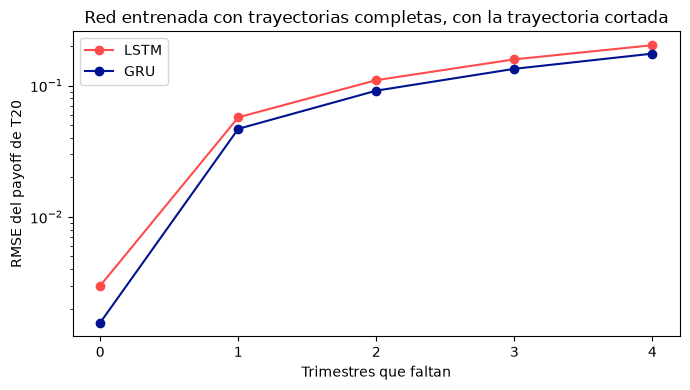

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
for tipo, color in zip(TIPOS_BUSQUEDA, [ROJO, AZUL]):
    m = res3[res3["red"] == tipo].groupby("faltan")["RMSE"].mean()
    ax.plot(m.index, m.values, marker="o", color=color, label=tipo)
ax.set(yscale="log", xlabel="Trimestres que faltan", ylabel="RMSE del payoff de T20",
       title="Red entrenada con trayectorias completas, con la trayectoria cortada")
ax.set_xticks(range(5)); ax.legend(); plt.tight_layout(); plt.show()

**Cómo leerlo.** El eje vertical está en escala logarítmica. Con la trayectoria completa (0 trimestres de menos) el error es mínimo: RMSE de 0,0016 en la GRU y de 0,0030 en la LSTM. Con un trimestre menos se multiplica por unas 30 en la GRU y por 19 en la LSTM, y con cuatro menos llega a 0,175 y 0,203. La GRU queda por debajo de la LSTM en todos los cortes.

#### Prima según los trimestres que ve la red

Con cada corte, de 1 a 20 trimestres vistos, la red predice el payoff de T20 y la prima sale como en el Montecarlo: la media de esos payoffs descontada a hoy con el factor 0,9512. Se compara con el Montecarlo de las mismas 10.000 simulaciones. Es la media de las 3 semillas. La tabla da la prima, el error y el error en porcentaje, y los dos gráficos siguientes la dibujan.

In [25]:
# Prima a t0 que da la red según los trimestres que ve (media de las 3 semillas)
filas = []
for tipo in TIPOS_BUSQUEDA:
    for s in SEMILLAS:
        red = cargar_final(tipo, s)
        with torch.no_grad():
            for j in range(1, 21):
                filas.append({"red": tipo, "j": j, "prima": DESC * red(x_te[:, :j]).mean().item()})
prima_j = pd.DataFrame(filas).groupby(["j", "red"])["prima"].mean().unstack()

mc = DESC * y_te.mean()                      # Montecarlo de las mismas 10.000 simulaciones
error_j = prima_j - mc
pd.concat({"prima": prima_j, "error": error_j, "error %": 100 * error_j / mc}, axis=1).round(4)

prima           error          error %         
red     GRU    LSTM     GRU    LSTM      GRU     LSTM
j                                                    
1    0.4584  0.2185  0.1613 -0.0787  54.2679 -26.4702
2    0.3761  0.2892  0.0789 -0.0080  26.5697  -2.6769
3    0.4018  0.3274  0.1047  0.0303  35.2232  10.1859
4    0.3825  0.3344  0.0853  0.0372  28.7132  12.5267
5    0.3648  0.3315  0.0677  0.0344  22.7727  11.5807
6    0.3449  0.3237  0.0478  0.0266  16.0746   8.9454
7    0.3252  0.3131  0.0281  0.0159   9.4468   5.3576
8    0.3057  0.3004  0.0086  0.0032   2.8819   1.0830
9    0.2873  0.2861 -0.0099 -0.0110  -3.3176  -3.7124
10   0.2723  0.2718 -0.0248 -0.0254  -8.3437  -8.5378
11   0.2625  0.2595 -0.0347 -0.0376 -11.6735 -12.6543
12   0.2571  0.2509 -0.0400 -0.0462 -13.4582 -15.5609
13   0.2556  0.2462 -0.0415 -0.0509 -13.9754 -17.1335
14   0.2570  0.2454 -0.0402 -0.0518 -13.5150 -17.4229
15   0.2608  0.2480 -0.0364 -0.0491 -12.2363 -16.5290
16   0.2661  0.2536 -0.0310 -0.0436 -10.4492 -14.6606
17   0.2728  0.2617 -0.0243 -0.0354  -8.1816 -11.9216
18   0.2804  0.2719 -0.0167 -0.0253  -5.6362  -8.5003
19   0.2886  0.2839 -0.0085 -0.0132  -2.8606  -4.4492
20   0.2973  0.2975  0.0002  0.0004   0.0526   0.1352

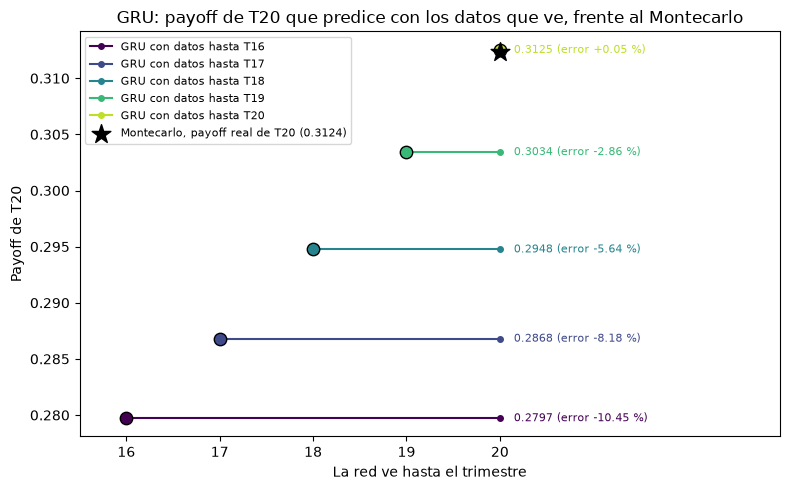

In [26]:
# Payoff de T20 que predice la red con los datos hasta k, frente al payoff real del Montecarlo (sin descuentos)
pago_j = prima_j / DESC                   # payoff medio de T20 predicho con k trimestres (la prima sin descontar)
payoff_mc = y_te.mean()                   # payoff medio real de T20 (Montecarlo, mismas 10.000 simulaciones)

KS = [16, 17, 18, 19, 20]                 # trimestre hasta el que ve datos la red
colores = plt.cm.viridis(np.linspace(0, 0.9, len(KS)))
fig, ax = plt.subplots(figsize=(8, 5))
for k, color in zip(KS, colores):
    p = pago_j.loc[k, "GRU"]
    ax.plot([k, 20], [p, p], color=color, marker="o", ms=4, label=f"GRU con datos hasta T{k}")
    ax.scatter(k, p, color=color, s=80, edgecolor="black", zorder=3)
    ax.annotate(f"{p:.4f} (error {100 * (p / payoff_mc - 1):+.2f} %)", xy=(20, p), xytext=(20.15, p),
                va="center", fontsize=8, color=color)
ax.scatter(20, payoff_mc, color="black", marker="*", s=200, zorder=4, label=f"Montecarlo, payoff real de T20 ({payoff_mc:.4f})")
ax.set(xlabel="La red ve hasta el trimestre", ylabel="Payoff de T20",
       title="GRU: payoff de T20 que predice con los datos que ve, frente al Montecarlo")
ax.set_xticks(KS); ax.set_xlim(15.5, 23); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Cómo leerlo.** Cada línea es la GRU con los datos hasta un trimestre distinto, de T16 a T20, y su valor es el payoff medio de T20 que predice. La estrella es el payoff real del Montecarlo. Con todos los datos la GRU acierta (+0,05 %), y cada trimestre que se le quita la deja más abajo: −2,86 % con datos hasta T19, −5,64 % hasta T18, −8,18 % hasta T17 y −10,45 % hasta T16.

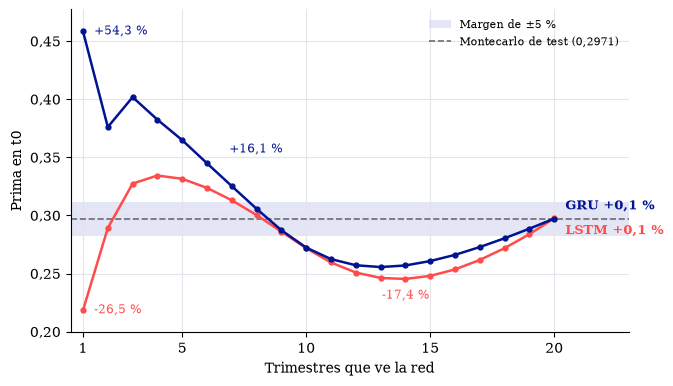

In [27]:
ROJO, AZUL, MARGEN = "#FF4B4B", "#001391", 0.05
coma = lambda v, d=4: f"{v:.{d}f}".replace(".", ",")
pct = lambda v: f"{v:+.1%}".replace(".", ",").replace("%", " %")
err = prima_j / mc - 1                                   # error relativo frente al Montecarlo

with plt.rc_context({"font.family": "serif", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E4E4EC"}):
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.axhspan(mc * (1 - MARGEN), mc * (1 + MARGEN), color="#D9DCF2", alpha=0.7, lw=0, label=f"Margen de ±{MARGEN*100:.0f} %")
    ax.axhline(mc, color="#6B6B75", ls="--", lw=1.2, label=f"Montecarlo de test ({coma(mc)})")
    for tipo, color in [("LSTM", ROJO), ("GRU", AZUL)]:
        y = prima_j[tipo]
        ax.plot(y.index, y, color=color, lw=1.8, marker="o", ms=3.5)
        ax.annotate(f"{tipo} {pct(err[tipo].iloc[-1])}", (20, y.iloc[-1]), xytext=(8, 9 if tipo == "GRU" else -9),
                    textcoords="offset points", color=color, fontweight="bold", fontsize=9, va="center")
        # error con 1 trimestre visto y en el peor punto desde el trimestre 6
        for k in [1, err.loc[6:, tipo].abs().idxmax()]:
            e = err.loc[k, tipo]
            ax.annotate(pct(e), (k, y[k]), xytext=(8 if k == 1 else 16 * (e > 0), 0 if k == 1 else (10 if e > 0 else -12)),
                        textcoords="offset points", color=color, fontsize=8.5, va="center",
                        ha="left" if k == 1 or e > 0 else "center")
    ax.set(xlabel="Trimestres que ve la red", ylabel="Prima en t0", xlim=(0.5, 23), xticks=[1, 5, 10, 15, 20])
    ax.margins(y=0.08)
    ax.yaxis.set_major_formatter(lambda v, _: coma(v, 2))
    ax.legend(frameon=False, fontsize=8)
    plt.show()

**Cómo leerlo.** Cada línea es una red con los datos de 1 a 20 trimestres. La línea gris discontinua es el Montecarlo de las mismas 10.000 simulaciones y la banda azul clara marca un ±5 % a su alrededor, solo como referencia visual del tamaño del error. Los porcentajes son el error frente al Montecarlo: con un solo trimestre, +54,3 % la GRU y −26,5 % la LSTM; pasado el comienzo común, el mayor es +16,1 % la GRU (con 6 trimestres) y −17,4 % la LSTM (con 14); con los 20 trimestres, +0,05 % y +0,14 %. Los 5 primeros trimestres son iguales en todas las simulaciones, así que con 5 o menos la red recibe siempre la misma entrada y da siempre el mismo valor.

#### 3.1 Conclusiones del bloque 3

Con la trayectoria completa la red acierta (RMSE de **0,0016** la GRU y **0,0030** la LSTM), pero en cuanto falta **un solo trimestre** el error se multiplica por unas 30 veces en la GRU (**0,047**) y por 19 en la LSTM (**0,057**). Con 4 trimestres de menos llega a **0,175** y **0,203**. Para comparar, predecir siempre la media da **0,482**: la red recortada sigue siendo mejor que eso (con 4 trimestres de menos reduce el error un 64 % la GRU y un 58 % la LSTM), pero muy lejos de su precisión con la trayectoria completa.

- **La GRU es mejor que la LSTM en todos los cortes.**
- **El error es sistemático:** el sesgo es negativo y crece con los trimestres que faltan (en la GRU de −0,009 a −0,033), así que la red infravalora el payoff.
- **Conclusión:** una red entrenada solo con trayectorias completas no sirve para valorar antes del vencimiento. Habría que entrenarla con trayectorias cortadas.

---
# **Conclusiones**

- **Mejor modelo: la GRU** de 2 capas y 64 neuronas, con learning rate 0,01, decaimiento 0,95 y sin dropout. En test, con tres semillas, se equivoca de media 0,0008 en el payoff (MAE) frente a 0,0017 de la mejor LSTM (2 capas, 32 neuronas, learning rate 0,001), y el R² es de 0,9999 en las dos. La peor GRU (0,00081) supera a la mejor LSTM (0,00140), y la GRU varía menos entre semillas (desviación de 0,00001 contra 0,0004).
- **Qué mejoró la red:** frente a la red base, el MSE en validación baja de 0,00020 a 0,000024 en la LSTM y de 0,00026 a 0,000014 en la GRU. La mejora viene sobre todo del learning rate y de dejar más épocas. La segunda capa ayuda poco (la LSTM de 1 capa llega a 0,00004 y la de 2 a 0,00002) y el dropout empeora el resultado, porque no hay sobreajuste que corregir.
- **Coste:** con las 100.000 simulaciones, la GRU (38.273 parámetros) tarda unos 22 minutos en entrenarse y la LSTM (13.217), unos 9.
- **Trayectorias cortadas:** sin reentrenar, el RMSE de la GRU pasa de 0,0016 con la trayectoria completa a 0,047 con un trimestre menos y a 0,175 con cuatro menos, siempre por debajo del de la LSTM (0,0030, 0,057 y 0,203) y del de predecir la media (0,482). La red infravalora el payoff, más cuanto menos ve: la prima de la GRU queda un 2,9 % por debajo del Montecarlo con un trimestre menos y un 10,5 % con cuatro menos. El siguiente paso natural es entrenarla con trayectorias cortadas.
- **Límites:** la GRU ganó con 64 neuronas, el extremo de la rejilla, y no se probó 128. No se exploraron el batch, el weight decay ni la RNN simple con learning rate alto. Son tres semillas con el mismo reparto de datos, y el test sale de la misma simulación que el entrenamiento, así que no dice qué pasaría con otras acciones u otros parámetros.
- **Prima:** sobre las 10.000 simulaciones de test, la GRU da 0,29729 y el Montecarlo 0,29714 (+0,05 %); la LSTM da 0,29754 (+0,14 %). La comparación completa con el Montecarlo y la fórmula cerrada, con los tiempos de cálculo, está en **resultados.ipynb**.